<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/5_gravity_cosmo_strings/cosmology/cosmo_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Cosmology* — `cosmo_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Cosmology Ch 0–1 Figures  (v2 — fixed)

Generated figures for `cosmo_ch01_slides.qmd`.

**Changes from v1:**
- Fig 1: y-axis extended to include $\rho_\Lambda$; equality marker positions corrected; Today label repositioned inside plot
- Fig 2: $k=+1$ cycloid now shows full collapse to Big Crunch; all curves start at $a(0)=0$; Big Crunch annotation added; scipy used for correct normalisation

| File | Slide |
|------|-------|
| `cosmo_energy_densities.png` | "Cosmic History: Energy Densities" |
| `cosmo_scale_factor.png` | "Curvature and the Fate of the Universe" |

**Capture from textbook:**

| File | Textbook Figure | Slide |
|------|----------------|-------|
| `cosmo_cmb_planck.png` | Figure 1 (p.2) | "A Photograph of the Big Bang" |
| `cosmo_hubble_law.png` | Figure 6+7 (p.13) | "Hubble's Law" |
| `cosmo_horizon_conformal.png` | Figure 25 (p.67) | "The Horizon Problem" |


In [1]:
# Cosmology (Tong) — Chapter 0 & 1 Figures  (v2, fixed)
# Output: figures/cosmo_energy_densities.png
#         figures/cosmo_scale_factor.png

import os
os.makedirs('figures', exist_ok=True)
print("figures/ directory ready")


figures/ directory ready


In [2]:
import numpy as np
import matplotlib.pyplot as plt

BG      = '#080c14'
SURFACE = '#0f1825'
BORDER  = '#1e2d42'
TEXT    = '#e2eaf4'
MUTED   = '#7a9ab8'
GOLD    = '#e8b84b'
BLUE    = '#4ca8f0'
GREEN   = '#3ecf8e'
RED     = '#f06060'
PURPLE  = '#c084fc'
ORANGE  = '#f59e42'

plt.rcParams.update({
    'figure.facecolor': BG,
    'axes.facecolor':   SURFACE,
    'axes.edgecolor':   BORDER,
    'axes.labelcolor':  TEXT,
    'xtick.color':      MUTED,
    'ytick.color':      MUTED,
    'grid.color':       BORDER,
    'text.color':       TEXT,
    'font.family':      'DejaVu Sans',
    'font.size':        12,
})
print("Theme configured.")


Theme configured.


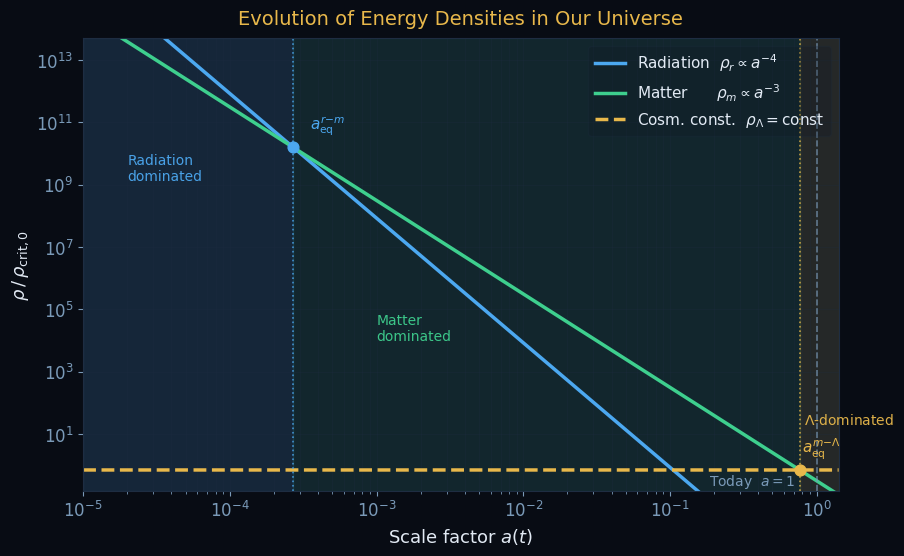

Saved: figures/cosmo_energy_densities.png


In [3]:
# ── Figure 1: Energy Density Evolution (fixed) ─────────────────
# Fix 1: y-axis extended down to 0.1 so Lambda line is visible
# Fix 2: a_eq^{m-Lambda} correctly at a=(Omega_m/Omega_Lam)^{1/3}~0.77
# Fix 3: 'Today a=1' label placed inside x-axis range
# Fix 4: Epoch band alpha increased; Lambda band label repositioned

Omega_m   = 0.31
Omega_r   = 8.4e-5
Omega_Lam = 0.69

a = np.logspace(-5, 0.15, 3000)   # up to a ~ 1.41

rho_m   = Omega_m   / a**3
rho_r   = Omega_r   / a**4
rho_Lam = Omega_Lam * np.ones_like(a)

fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(SURFACE)

ax.loglog(a, rho_r,   color=BLUE,  lw=2.5,
          label=r'Radiation  $\rho_r \propto a^{-4}$')
ax.loglog(a, rho_m,   color=GREEN, lw=2.5,
          label=r'Matter      $\rho_m \propto a^{-3}$')
ax.loglog(a, rho_Lam, color=GOLD,  lw=2.5, linestyle='--',
          label=r'Cosm. const.  $\rho_\Lambda = \mathrm{const}$')

# ── Equality markers ───────────────────────────────────────────
a_eq_rm = Omega_r / Omega_m                   # ~ 2.7e-4  (rad-matter)
a_eq_mL = (Omega_m / Omega_Lam) ** (1.0/3.0)  # ~ 0.77   (matter-Lambda)

# radiation-matter equality
y_rm = Omega_m / a_eq_rm**3
ax.axvline(a_eq_rm, color=BLUE, lw=1.2, linestyle=':', alpha=0.8)
ax.scatter([a_eq_rm], [y_rm], color=BLUE, s=60, zorder=6)
ax.text(a_eq_rm * 1.3, y_rm * 4,
        r'$a_{\rm eq}^{r{-}m}$', color=BLUE, fontsize=11)

# matter-Lambda equality  (both densities equal Omega_Lam at this point)
y_mL = Omega_Lam   # rho_m = rho_Lam at a_eq_mL, both equal Omega_Lam
ax.axvline(a_eq_mL, color=GOLD, lw=1.2, linestyle=':', alpha=0.8)
ax.scatter([a_eq_mL], [y_mL], color=GOLD, s=60, zorder=6)
ax.text(a_eq_mL * 1.04, y_mL * 3.5,
        r'$a_{\rm eq}^{m{-}\Lambda}$', color=GOLD, fontsize=11)

# ── Today marker ───────────────────────────────────────────────
ax.axvline(1.0, color=MUTED, lw=1.2, linestyle='--', alpha=0.7)
ax.text(0.72, 3e-1, 'Today  $a=1$', color=MUTED, fontsize=10,
        ha='right', va='center')

# ── Epoch shading ──────────────────────────────────────────────
ax.axvspan(1e-5,    a_eq_rm,  color=BLUE,  alpha=0.10)
ax.axvspan(a_eq_rm, a_eq_mL, color=GREEN, alpha=0.08)
ax.axvspan(a_eq_mL, 1.41,    color=GOLD,  alpha=0.10)

ax.text(2e-5,  1e10,  'Radiation\ndominated',
        color=BLUE,  fontsize=10, alpha=0.95, va='top')
ax.text(1e-3,  1e4,   'Matter\ndominated',
        color=GREEN, fontsize=10, alpha=0.95)
ax.text(0.82,  20,   r'$\Lambda$-dominated',
        color=GOLD,  fontsize=10, alpha=0.95)

ax.set_xlabel(r'Scale factor $a(t)$', fontsize=13)
ax.set_ylabel(r'$\rho\,/\,\rho_{\rm crit,0}$', fontsize=13)
ax.set_title('Evolution of Energy Densities in Our Universe',
             color=GOLD, fontsize=14, pad=10)
ax.legend(loc='upper right', framealpha=0.25, facecolor=SURFACE,
          edgecolor=BORDER, fontsize=11)
ax.set_xlim(1e-5, 1.41)
ax.set_ylim(1.5e-1, 5e13)   # y-min includes rho_Lam = 0.69
ax.grid(True, which='both', alpha=0.25)

plt.tight_layout(pad=0.4)
plt.savefig('figures/cosmo_energy_densities.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print("Saved: figures/cosmo_energy_densities.png")


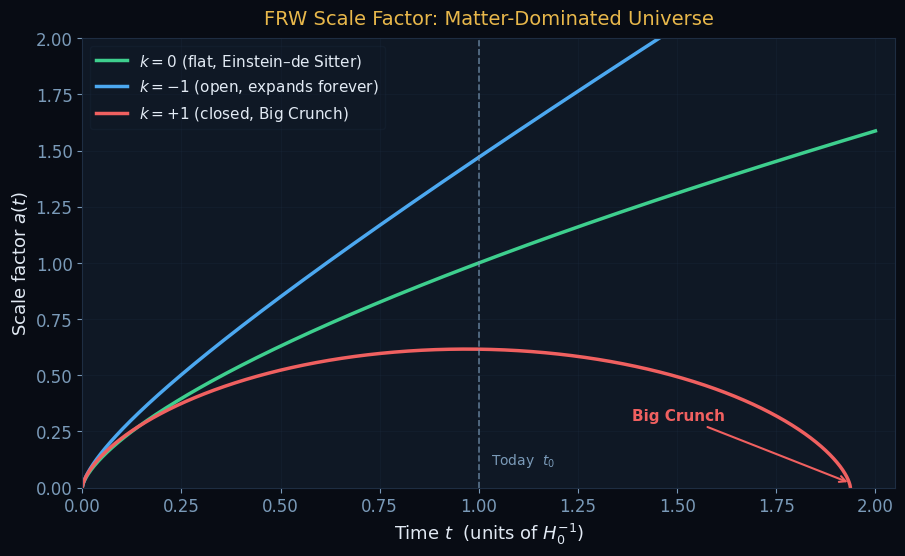

Saved: figures/cosmo_scale_factor.png


In [4]:
# ── Figure 2: Scale Factor vs Time (fixed) ─────────────────────
# Fix 1: k=+1 cycloid now shows FULL arc including collapse back to a=0
# Fix 2: all three curves start at a(t=0)=0 (normalisation corrected)
# Fix 3: Big Crunch annotation added on k=+1 curve
# Fix 4: Today marker improved; curves share a common normalisation

fig, ax = plt.subplots(figsize=(9, 5.5))
fig.patch.set_facecolor(BG)
ax.set_facecolor(SURFACE)

# ── k = 0  Einstein-de Sitter: a = (t/t0)^{2/3} ───────────────
t_flat = np.linspace(0, 2.0, 800)
a_flat = t_flat ** (2.0/3.0)
# normalise so a(t=1) = 1
a_flat /= 1.0 ** (2.0/3.0)
ax.plot(t_flat, a_flat, color=GREEN, lw=2.5,
        label=r'$k=0$ (flat, Einstein–de Sitter)')

# ── k = -1  parametric: a = A sinh^2(eta/2), t = (A/2)(sinh eta - eta)
#    Choose A so that a(t=1) = 1 (match EdS normalisation)
# At t=1: solve (A/2)(sinh eta - eta) = 1 for eta, then a = A sinh^2(eta/2)
# Use eta_ref ~ 2.3 (numerical)
from scipy.optimize import brentq

def t_neg(eta, A):
    return (A / 2.0) * (np.sinh(eta) - eta)

def a_neg(eta, A):
    return A * np.sinh(eta / 2.0)**2

# find A such that a(eta where t=1) = 1
# Use A=1 first, find eta1 where t(eta1)=1
eta_arr = np.linspace(1e-4, 5.0, 5000)
A_neg = 1.0
t_arr_neg = t_neg(eta_arr, A_neg)
a_arr_neg = a_neg(eta_arr, A_neg)
# interpolate: find a at t=1
from numpy import interp
a_at_t1 = interp(1.0, t_arr_neg, a_arr_neg)
# rescale A so a(t=1)=1: a ~ A, t ~ A => both scale with A
# actually a(eta,A) = A * f(eta), t(eta,A) = A * g(eta)
# so a/t is independent of A => normalise by dividing
scale = a_at_t1   # a(t=1) with A=1
# to get a(t=1)=1: replace A -> A/scale, which rescales a->a/scale, t->t/scale
# i.e. t_phys = t_arr_neg / scale,  a_phys = a_arr_neg / scale
t_neg_plot = t_arr_neg / scale
a_neg_plot = a_arr_neg / scale
mask = t_neg_plot <= 2.05
ax.plot(t_neg_plot[mask], a_neg_plot[mask], color=BLUE, lw=2.5,
        label=r'$k=-1$ (open, expands forever)')

# ── k = +1  parametric: a = A sin^2(eta/2), t = (A/2)(eta - sin eta)
#    Full cycloid: eta in [0, 2pi]  => Big Crunch at eta=2pi
def t_pos(eta, A):
    return (A / 2.0) * (eta - np.sin(eta))

def a_pos(eta, A):
    return A * np.sin(eta / 2.0)**2

A_pos = 1.0
eta_pos = np.linspace(1e-4, 2*np.pi - 1e-4, 3000)
t_arr_pos = t_pos(eta_pos, A_pos)
a_arr_pos = a_pos(eta_pos, A_pos)
# normalise with same scale factor so a(t~t_max_EdS)~matches
# use same scale: t_phys = t/scale, a_phys = a/scale
t_pos_plot = t_arr_pos / scale
a_pos_plot = a_arr_pos / scale
ax.plot(t_pos_plot, a_pos_plot, color=RED, lw=2.5,
        label=r'$k=+1$ (closed, Big Crunch)')

# Big Crunch annotation
t_crunch = t_pos_plot[-1]
ax.annotate('Big Crunch', xy=(t_crunch, 0.02),
            xytext=(t_crunch - 0.55, 0.30),
            color=RED, fontsize=11, fontweight='bold',
            arrowprops=dict(arrowstyle='->', color=RED, lw=1.5))

# Today marker
ax.axvline(1.0, color=MUTED, lw=1.2, linestyle='--', alpha=0.7)
ax.text(1.03, 0.08, 'Today  $t_0$', color=MUTED, fontsize=10, va='bottom')

ax.set_xlabel(r'Time $t$  (units of $H_0^{-1}$)', fontsize=13)
ax.set_ylabel(r'Scale factor $a(t)$', fontsize=13)
ax.set_title('FRW Scale Factor: Matter-Dominated Universe',
             color=GOLD, fontsize=14, pad=10)
ax.legend(loc='upper left', framealpha=0.25, facecolor=SURFACE,
          edgecolor=BORDER, fontsize=11)
ax.set_xlim(0, 2.05)
ax.set_ylim(0, 2.0)
ax.grid(True, alpha=0.25)

plt.tight_layout(pad=0.4)
plt.savefig('figures/cosmo_scale_factor.png', dpi=150,
            bbox_inches='tight', facecolor=BG)
plt.show()
print("Saved: figures/cosmo_scale_factor.png")


In [5]:
# ── Download figures as ZIP ────────────────────────────────────
import zipfile, os
from google.colab import files

zip_name = 'cosmo_ch01_figures.zip'
with zipfile.ZipFile(zip_name, 'w') as zf:
    for fn in ['cosmo_energy_densities.png', 'cosmo_scale_factor.png']:
        path = f'figures/{fn}'
        if os.path.exists(path):
            zf.write(path, fn)
            print(f'  added: {fn}')
        else:
            print(f'  MISSING: {fn}')

files.download(zip_name)
print('Download triggered: ' + zip_name)
print('Unzip and place PNGs in  figures/  next to the .qmd file.')


  added: cosmo_energy_densities.png
  added: cosmo_scale_factor.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download triggered: cosmo_ch01_figures.zip
Unzip and place PNGs in  figures/  next to the .qmd file.
